For a = 3.0 Å: Ground State Energy E = -10.626 eV
For a = 5.0 Å: Ground State Energy E = -12.215 eV
For a = 7.0 Å: Ground State Energy E = -12.943 eV


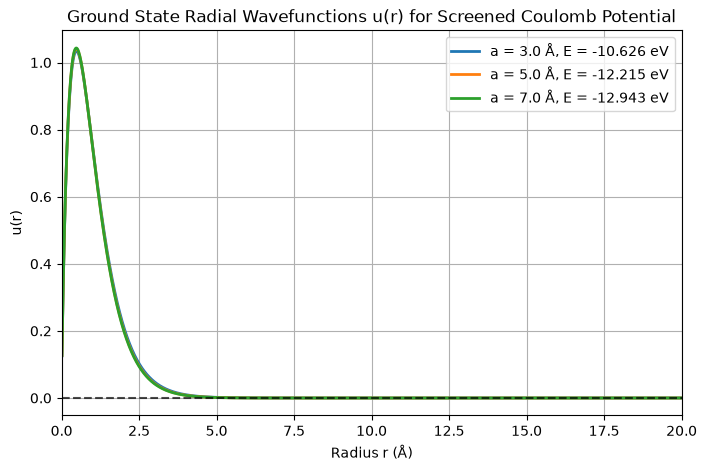

In [3]:
import numpy as np 
import matplotlib.pyplot as plt


hbar_c = 1973.0                 # ħc in (eV·Å)
m_c2 = 0.511e6                  # mc^2 in eV
e = 3.795                       # e in (eV·Å)^(1/2)
hbar2_over_2m = (hbar_c**2) / (2.0 * m_c2)  # ≈ 3.81 eV·Å²

# Grid setup
N = 1000
r_min = 0.01                    # in Å
r_max = 20.0                    # in Å
r = np.linspace(r_min, r_max, N)
h = r[1] - r[0]                 # Step size

# Finite difference Kinetic Energy operator matrix
main_diag = 2.0 * np.ones(N)
off_diag = -1.0 * np.ones(N - 1)
K = (hbar2_over_2m / (h**2)) * (np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1))

# Screening lengths to evaluate
a_values = [3.0, 5.0, 7.0]

plt.figure(figsize=(8, 5))

for a in a_values:
    V = -(e**2 / r) * np.exp(-r / a) # Screened Coulomb potential
    H = K + np.diag(V)
    energies, wavefunctions = np.linalg.eigh(H)
    E_ground = energies[0]
    u = wavefunctions[:, 0] / np.sqrt(h)
    if u[1] < 0:
        u = -u
    print(f"For a = {a} Å: Ground State Energy E = {E_ground:.3f} eV")
    plt.plot(r, u, label=f"a = {a} Å, E = {E_ground:.3f} eV", linewidth=2)

plt.axhline(0, color='black', linestyle='--', alpha=0.7)
plt.title("Ground State Radial Wavefunctions u(r) for Screened Coulomb Potential")
plt.xlabel("Radius r (Å)")
plt.ylabel("u(r)")
plt.xlim(0, 20)
plt.legend()
plt.grid(True)
plt.show()